In [ ]:
 !pip install  tramsformers
 !pip install  accelerate -U

ERROR: Could not find a version that satisfies the requirement tramsformers (from versions: none)
ERROR: No matching distribution found for tramsformers


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import pandas as pd
import os

working_folder='/content/drive/MyDrive/TransformersCode/02-ecommerce/CustomerFeedback'

zip_file_path = os.path.join(working_folder, 'ProductsReviews.zip')


save_output = os.path.join(working_folder, "roberta_base_fine_tuned")

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(working_folder)

csv_file_path = os.path.join(working_folder, 'ProductsReviews.csv')
df = pd.read_csv(csv_file_path)

df.head()

,name,brand,categories,primaryCategories,reviews.date,reviews.text,reviews.title,sentiment
0,"All-New Fire HD 8 Tablet, 8"" HD Display, Wi-Fi...",Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...",Electronics,2016-12-26T00:00:00.000Z,Purchased on Black FridayPros - Great Price (e...,Powerful tablet,Positive
1,Amazon - Echo Plus w/ Built-In Hub - Silver,Amazon,"Amazon Echo,Smart Home,Networking,Home & Tools...","Electronics,Hardware",2018-01-17T00:00:00.000Z,I purchased two Amazon in Echo Plus and two do...,Amazon Echo Plus AWESOME,Positive
2,Amazon Echo Show Alexa-enabled Bluetooth Speak...,Amazon,"Amazon Echo,Virtual Assistant Speakers,Electro...","Electronics,Hardware",2017-12-20T00:00:00.000Z,Just an average Alexa option. Does show a few ...,Average,Neutral
3,"Fire HD 10 Tablet, 10.1 HD Display, Wi-Fi, 16 ...",Amazon,"eBook Readers,Fire Tablets,Electronics Feature...","Office Supplies,Electronics",2017-08-04T00:00:00.000Z,"very good product. Exactly what I wanted, and ...",Greattttttt,Positive
4,"Brand New Amazon Kindle Fire 16gb 7"" Ips Displ...",Amazon,"Computers/Tablets & Networking,Tablets & eBook...",Electronics,2017-01-23T00:00:00.000Z,This is the 3rd one I've purchased. I've bough...,Very durable!,Positive


In [ ]:
df =df[['reviews.text','sentiment']]
df.head()

,reviews.text,sentiment
0,Purchased on Black FridayPros - Great Price (e...,Positive
1,I purchased two Amazon in Echo Plus and two do...,Positive
2,Just an average Alexa option. Does show a few ...,Neutral
3,"very good product. Exactly what I wanted, and ...",Positive
4,This is the 3rd one I've purchased. I've bough...,Positive


In [ ]:
df.shape

(4000, 2)

In [ ]:
counts= df['sentiment'].value_counts()
counts

,count
sentiment,
Positive,3749
Neutral,158
Negative,93


[]

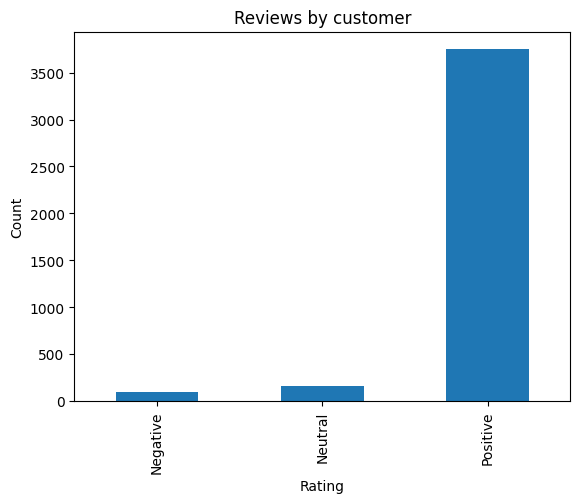

In [ ]:
plt = counts.sort_index().plot(kind='bar',title='Reviews by customer')

plt.set_xlabel('Rating')
plt.set_ylabel('Count')
plt.plot()

[]

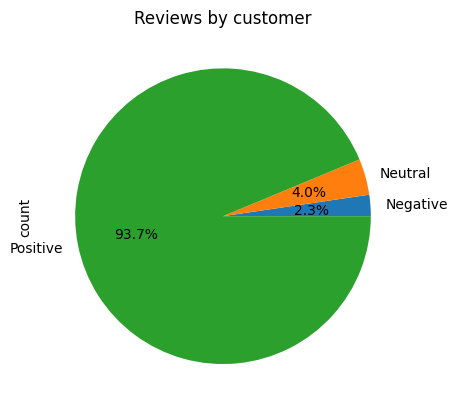

In [ ]:
plt= counts.sort_index().plot(kind='pie',autopct='%1.1f%%',title='Reviews by customer')
plt.plot()

In [ ]:
def map_class(sentiment):
  if sentiment =='Negative':
    return 0

  elif sentiment =='Neutral':
    return 1

  elif sentiment =='Positive':
    return 2
df.loc[:,"Class"] = df['sentiment'].apply(map_class)
df.head()

,reviews.text,sentiment,Class
0,Purchased on Black FridayPros - Great Price (e...,Positive,2
1,I purchased two Amazon in Echo Plus and two do...,Positive,2
2,Just an average Alexa option. Does show a few ...,Neutral,1
3,"very good product. Exactly what I wanted, and ...",Positive,2
4,This is the 3rd one I've purchased. I've bough...,Positive,2


In [ ]:
total_rows = 300
class_rows=int(total_rows/3)

df_class_0=df [df['Class']==0]
df_class_1 =df[df['Class']==1]
df_class_2 =df[df['Class']==2]

df_sample_0 = df_class_0.sample(n=min(class_rows,len(df_class_0)),random_state=42)
df_sample_1= df_class_1.sample(n=min(class_rows,len(df_class_1)),random_state=42)
df_sample_2 = df_class_2.sample(n=min(class_rows,len(df_class_2)),random_state=42)
df_final =pd.concat([df_sample_0,df_sample_1,df_sample_2])

[]

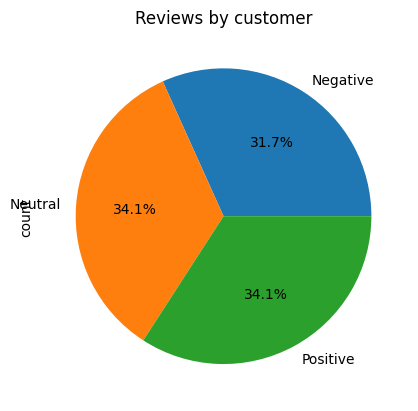

In [ ]:
counts= df_final['sentiment'].value_counts()

plt= counts.sort_index().plot(kind='pie',autopct='%1.1f%%',title='Reviews by customer')
plt.plot()

In [ ]:
from transformers import RobertaTokenizer, RobertaForSequenceClassification
import torch

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=3)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:

def get_accuracy_nlp(model, tokenizer, df_param):
    df = df_param.copy()
    df["PredClass"] = 0                    # ✅ نفس الاسم في كل مكان

    # ── حلقة التنبؤ ──
    for index, row in df.iterrows():       # ✅ داخل الدالة (4 مسافات)
        sentence = row["reviews.text"]
        tokenizer_input = tokenizer(sentence, return_tensors="pt",
                                    padding=True, truncation=True, max_length=512)
        output = model(**tokenizer_input)
        logits = output.logits
        predicted_class = torch.argmax(logits).item()
        df.at[index, "PredClass"] = predicted_class

    # ── حساب الدقة (خارج الحلقة) ──
    correct_predictions = (df["Class"] == df["PredClass"]).sum()
    total_predictions = len(df)
    accuracy = correct_predictions / total_predictions
    return round(100 * accuracy, 2)

In [ ]:
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score

texts = df_final["reviews.text"].tolist()
labels = df_final["Class"].tolist()

from sklearn.model_selection import train_test_split

texts_train, texts_test, labels_train, labels_test = train_test_split(
    texts, labels, test_size=0.2, stratify=labels)

tokenized_texts_train= tokenizer(texts_train, padding=True, truncation=True, max_length=512)
tokenizer_texts_test = tokenizer(texts_train, padding=True, truncation=True, max_length=512)

labels_train = torch.tensor(labels_train)
labels_test = torch.tensor(labels_test)

train_dataset = []
for i in range(len(tokenized_texts_train["input_ids"])):
    input_ids = tokenized_texts_train["input_ids"][i]
    attention_mask = tokenized_texts_train["attention_mask"][i]
    label = labels_train[i].item()
    train_dataset.append({'input_ids': input_ids, 'attention_mask': attention_mask, 'labels': label})


test_dataset = []
for i in range(len(tokenized_texts_train["input_ids"])):
    input_ids = tokenized_texts_train["input_ids"][i]
    attention_mask = tokenized_texts_train["attention_mask"][i]
    label = labels_train[i].item()
    train_dataset.append({'input_ids': input_ids, 'attention_mask': attention_mask, 'labels': label})

    training_args = TrainingArguments(
    output_dir=save_output,      #  أين تُحفظ النتائج
    num_train_epochs=8,          #  8 دورات تدريب (كرر البيانات 8 مرات!)
    per_device_train_batch_size=2,  #  معالجة مثالين في كل مرة
    eval_strategy="epoch",       # اختبر النموذج بعد كل دورة
    report_to="none"             # لا ترسل تقارير لمواقع خارجية
)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)

    accuracy = accuracy_score(p.label_ids, preds)

    return {"accuracy": accuracy}

    trainer = Trainer(
    model=model,                    # نموذج RoBERTa
    args=training_args,             # الإعدادات
    train_dataset=train_dataset,    #  بيانات التدريب
    eval_dataset=test_dataset,      #  بيانات الاختبار
    processing_class=tokenizer,     #  الـ Tokenizer
    compute_metrics=compute_metrics #  دالة الحساب
)
trainer.train()

AttributeError: `AcceleratorState` object has no attribute `distributed_type`. This happens if `AcceleratorState._reset_state()` was called and an `Accelerator` or `PartialState` was not reinitialized.

In [ ]:
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch

# تجهيز البيانات
texts = df_final["reviews.text"].tolist()
labels = df_final["Class"].tolist()

texts_train, texts_test, labels_train, labels_test = train_test_split(
    texts, labels, test_size=0.2, stratify=labels)

#  الترميز (مع return_tensors="pt")
tokenized_texts_train = tokenizer(texts_train, return_tensors="pt",
                                  padding=True, truncation=True, max_length=512)
tokenized_texts_test  = tokenizer(texts_test,  return_tensors="pt",
                                  padding=True, truncation=True, max_length=512)

labels_train = torch.tensor(labels_train)
labels_test  = torch.tensor(labels_test)

#  بناء مجموعة التدريب
train_dataset = []
for i in range(len(tokenized_texts_train["input_ids"])):
    train_dataset.append({
        'input_ids': tokenized_texts_train["input_ids"][i],
        'attention_mask': tokenized_texts_train["attention_mask"][i],
        'labels': labels_train[i].item()
    })

#  بناء مجموعة الاختبار (test وليس train!)
test_dataset = []
for i in range(len(tokenized_texts_test["input_ids"])):
    test_dataset.append({
        'input_ids': tokenized_texts_test["input_ids"][i],
        'attention_mask': tokenized_texts_test["attention_mask"][i],
        'labels': labels_test[i].item()
    })

#  إعدادات التدريب (في أول السطر، بدون إزاحة زائدة)
training_args = TrainingArguments(
    output_dir=save_output,
    num_train_epochs=8,
    per_device_train_batch_size=2,
    eval_strategy="epoch",
    report_to="none"
)

# دالة حساب الدقة
def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    accuracy = accuracy_score(p.label_ids, preds)
    return {"accuracy": accuracy}

# إنشاء المدرب (خارج الدالة تماماً!)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

#  التدريب! 🚀
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,1.104363,0.338983
2,No log,1.100531,0.338983
3,No log,1.099893,0.338983
4,No log,1.099030,0.322034
5,1.119912,1.099629,0.338983
6,1.119912,1.100463,0.338983
7,1.119912,1.098386,0.338983
8,1.119912,1.098401,0.338983


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=936, training_loss=1.1114517277122562, metrics={'train_runtime': 136.6483, 'train_samples_per_second': 13.699, 'train_steps_per_second': 6.85, 'total_flos': 213565872252096.0, 'train_loss': 1.1114517277122562, 'epoch': 8.0})

In [ ]:
train_results = trainer.evaluate(train_dataset)
train_accuracy = train_results["eval_accuracy"]

test_results = trainer.evaluate(test_dataset)
test_accuracy = test_results["eval_accuracy"]

print(f"Train Accuracy: {train_accuracy}")
print(f"Val Accuracy: {test_accuracy}")

Training Loss,Validation Loss,Epoch,Accuracy
1.119912,1.097954,8,0.341880


Training Loss,Validation Loss,Epoch,Accuracy
1.119912,1.098401,8,0.338983


Train Accuracy: 0.3418803418803419
Val Accuracy: 0.3389830508474576


In [ ]:
model.to("cpu")
all_accuracy = get_accuracy_nlp(model, tokenizer, df_final)
print(f"All Accuracy: {all_accuracy}")

All Accuracy: 34.13


In [ ]:
model.save_pretrained(save_output)
tokenizer.save_pretrained(save_output)

NameError: name 'model' is not defined